# DS605 Lab 8: Decision Trees and Support Vector Machines

**Dataset:** Banknote Authentication Dataset

----------------

## Part A: Decision Tree from Scratch

In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

columns = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    "banknote+authentication/data_banknote_authentication.txt",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nClass distribution:")
print(df["class"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (1372, 5)

First five rows:


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0



Class distribution:
class
0    762
1    610
Name: count, dtype: int64

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64


In [72]:
# Select Features and Split the Dataset
from sklearn.model_selection import train_test_split

X = df[["variance", "skewness"]].to_numpy()
y = df["class"].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Training class distribution:", np.bincount(y_train))
print("Testing class distribution:", np.bincount(y_test))

Training samples: 1097
Testing samples: 275
Number of features: 2
Training class distribution: [609 488]
Testing class distribution: [153 122]


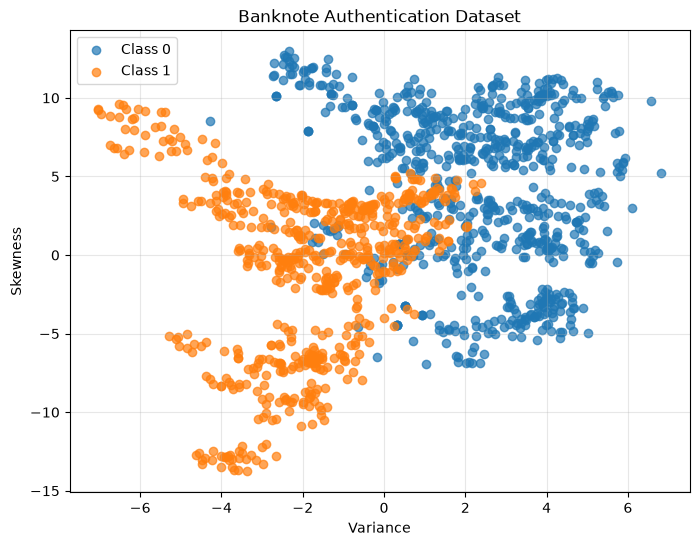

In [73]:
# Visualize the Selected Features
plt.figure(figsize=(8, 6))

for label in np.unique(y):
    plt.scatter(
        X[y == label, 0],
        X[y == label, 1],
        label=f"Class {label}",
        alpha=0.7
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Authentication Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [74]:
# Implement Gini Impurity and Entropy from Scratch
def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


print("Gini of pure node:", gini_impurity(np.array([0, 0, 0, 0])))
print("Entropy of pure node:", entropy(np.array([0, 0, 0, 0])))

print("Gini of mixed node:", gini_impurity(np.array([0, 0, 1, 1])))
print("Entropy of mixed node:", entropy(np.array([0, 0, 1, 1])))

Gini of pure node: 0.0
Entropy of pure node: -0.0
Gini of mixed node: 0.5
Entropy of mixed node: 1.0


In [75]:
#Calculate Weighted Impurity and Information Gain
def information_gain(y, y_left, y_right, criterion="gini"):
    impurity_function = (
        gini_impurity if criterion == "gini" else entropy
    )

    parent_impurity = impurity_function(y)

    n = len(y)
    n_left = len(y_left)
    n_right = len(y_right)

    weighted_impurity = (
        (n_left / n) * impurity_function(y_left)
        + (n_right / n) * impurity_function(y_right)
    )

    return parent_impurity - weighted_impurity


y_parent = np.array([0, 0, 1, 1])
y_left = np.array([0, 0])
y_right = np.array([1, 1])

print("Gini gain:", information_gain(y_parent, y_left, y_right, "gini"))
print("Entropy gain:", information_gain(y_parent, y_left, y_right, "entropy"))

Gini gain: 0.5
Entropy gain: 1.0


In [76]:
# Find the Best Feature-Threshold Split
def best_split(X, y, criterion="gini", min_samples_leaf=1):
    n_samples, n_features = X.shape

    if n_samples < 2 * min_samples_leaf:
        return None, None, None

    impurity_function = (
        gini_impurity if criterion == "gini" else entropy
    )

    parent_impurity = impurity_function(y)

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        values = np.unique(X[:, feature])

        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            if (len(y_left) < min_samples_leaf or
                    len(y_right) < min_samples_leaf):
                continue

            weighted_impurity = (
                len(y_left) / n_samples * impurity_function(y_left)
                + len(y_right) / n_samples * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_gain

In [77]:
feature, threshold, gain = best_split(
    X_train,
    y_train,
    criterion="gini"
)

if feature is not None:
    print("Best feature:", ["variance", "skewness"][feature])
    print("Best threshold:", threshold)
    print("Gini gain:", gain)
else:
    print("No valid split found.")

Best feature: variance
Best threshold: 0.7651
Gini gain: 0.24209450956617234


In [78]:
feature, threshold, gain = best_split(
    X_train,
    y_train,
    criterion="entropy"
)

if feature is not None:
    print("Best feature:", ["variance", "skewness"][feature])
    print("Best threshold:", threshold)
    print("Information gain:", gain)
else:
    print("No valid split found.")

Best feature: variance
Best threshold: 0.7651
Information gain: 0.40280462579181764


In [79]:
#Build the Decision Tree Recursively
class TreeNode:
    def __init__(
        self,
        feature=None,
        threshold=None,
        left=None,
        right=None,
        value=None
    ):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value

    def is_leaf(self):
        return self.value is not None

In [80]:
class ManualDecisionTree:
    def __init__(
        self,
        criterion="gini",
        max_depth=5,
        min_samples_split=2,
        min_samples_leaf=1
    ):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None

    def fit(self, X, y):
        self.root = self._grow_tree(X, y, depth=0)
        return self

    def _grow_tree(self, X, y, depth):
        n_samples = len(y)
        n_classes = len(np.unique(y))

        if (
            n_classes == 1
            or n_samples < self.min_samples_split
            or n_samples < 2 * self.min_samples_leaf
            or (self.max_depth is not None and depth >= self.max_depth)
        ):
            return TreeNode(value=self._majority_class(y))

        feature, threshold, gain = best_split(
            X,
            y,
            criterion=self.criterion,
            min_samples_leaf=self.min_samples_leaf
        )

        if feature is None or gain <= 0:
            return TreeNode(value=self._majority_class(y))

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        left_child = self._grow_tree(
            X[left_mask], y[left_mask], depth + 1
        )

        right_child = self._grow_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        return TreeNode(
            feature=feature,
            threshold=threshold,
            left=left_child,
            right=right_child
        )

    def _majority_class(self, y):
        classes, counts = np.unique(y, return_counts=True)
        return classes[np.argmax(counts)]

    def _predict_one(self, x, node):
        if node.is_leaf():
            return node.value

        if x[node.feature] <= node.threshold:
            return self._predict_one(x, node.left)

        return self._predict_one(x, node.right)

    def predict(self, X):
        return np.array([
            self._predict_one(x, self.root)
            for x in X
        ])

In [81]:
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

manual_tree.fit(X_train, y_train)

y_train_pred = manual_tree.predict(X_train)
y_test_pred = manual_tree.predict(X_test)

print("Training predictions:", y_train_pred[:10])
print("Testing predictions:", y_test_pred[:10])
print("Training accuracy:", np.mean(y_train_pred == y_train))
print("Testing accuracy:", np.mean(y_test_pred == y_test))

Training predictions: [1 1 0 1 1 1 0 1 0 0]
Testing predictions: [0 1 0 1 1 1 0 0 0 1]
Training accuracy: 0.9480401093892434
Testing accuracy: 0.9309090909090909


In [82]:
#Evaluate the manual tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_test_pred, zero_division=0))

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

Accuracy: 0.9309090909090909
Precision: 0.8814814814814815
Recall: 0.9754098360655737
F1-score: 0.9260700389105059

Confusion matrix:
[[137  16]
 [  3 119]]

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.90      0.94       153
           1       0.88      0.98      0.93       122

    accuracy                           0.93       275
   macro avg       0.93      0.94      0.93       275
weighted avg       0.94      0.93      0.93       275



In [83]:
# Visualize the Learned Manual Decision Tree
def print_tree(node, feature_names, depth=0):
    indent = "    " * depth

    if node.is_leaf():
        print(f"{indent}Predict class: {node.value}")
        return

    feature_name = feature_names[node.feature]

    print(
        f"{indent}if {feature_name} <= {node.threshold:.4f}:"
    )
    print_tree(node.left, feature_names, depth + 1)

    print(f"{indent}else:")
    print_tree(node.right, feature_names, depth + 1)


feature_names = ["variance", "skewness"]

print_tree(manual_tree.root, feature_names)

if variance <= 0.7651:
    if skewness <= 5.1608:
        if variance <= 0.3202:
            if variance <= -0.4586:
                if skewness <= 0.0548:
                    Predict class: 1
                else:
                    Predict class: 1
            else:
                if skewness <= -0.1666:
                    Predict class: 1
                else:
                    Predict class: 1
        else:
            if skewness <= 3.2197:
                if variance <= 0.7406:
                    Predict class: 0
                else:
                    Predict class: 1
            else:
                Predict class: 1
    else:
        if variance <= -3.4311:
            if variance <= -4.3819:
                Predict class: 1
            else:
                if variance <= -4.2554:
                    Predict class: 0
                else:
                    Predict class: 1
        else:
            if skewness <= 5.3646:
                if variance <= 0.6458:
      

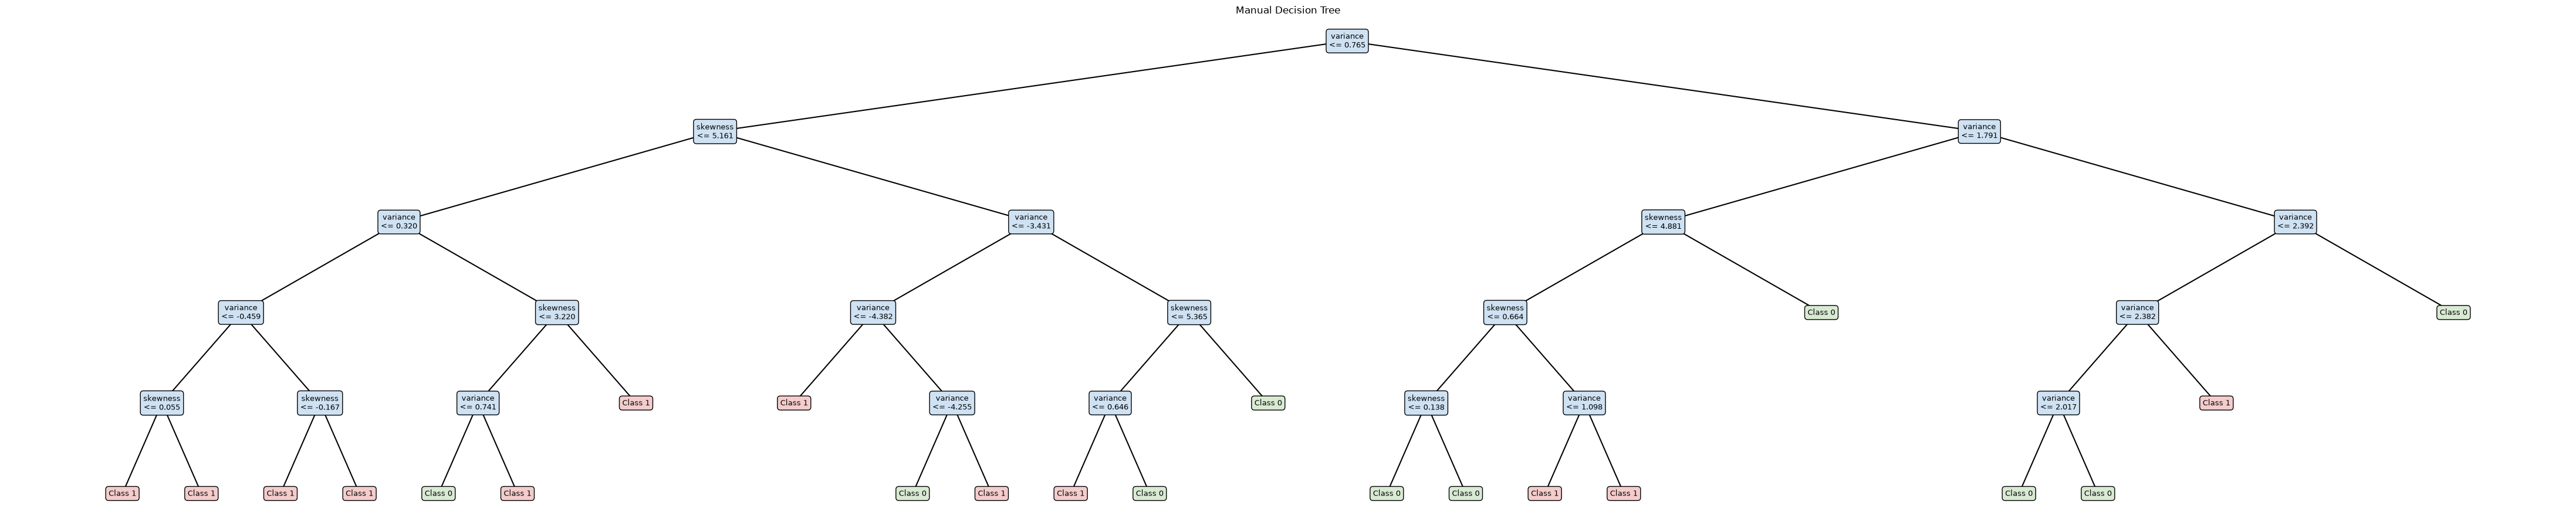

In [84]:
def count_leaves(node):
    if node.is_leaf():
        return 1
    return count_leaves(node.left) + count_leaves(node.right)


def tree_depth(node):
    if node.is_leaf():
        return 0
    return 1 + max(tree_depth(node.left), tree_depth(node.right))


def draw_tree(node, feature_names):
    total_leaves = count_leaves(node)
    max_depth = tree_depth(node)

    fig, ax = plt.subplots(
        figsize=(max(12, total_leaves * 2), max(5, max_depth * 1.8))
    )

    leaf_position = [0]

    def draw_node(current, depth, x_start, x_end, parent=None):
        x = (x_start + x_end) / 2
        y_pos = -depth

        if current.is_leaf():
            label = f"Class {current.value}"
            color = "#d9ead3" if current.value == 0 else "#f4cccc"
            leaf_position[0] += 1
        else:
            label = (
                f"{feature_names[current.feature]}\n"
                f"<= {current.threshold:.3f}"
            )
            color = "#cfe2f3"

        ax.text(
            x, y_pos, label,
            ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", fc=color, ec="black")
        )

        if parent is not None:
            ax.plot([parent[0], x], [parent[1], y_pos], color="black")

        if not current.is_leaf():
            midpoint = (x_start + x_end) / 2

            draw_node(
                current.left, depth + 1,
                x_start, midpoint, (x, y_pos)
            )
            draw_node(
                current.right, depth + 1,
                midpoint, x_end, (x, y_pos)
            )

    draw_node(node, 0, 0, total_leaves)

    ax.set_title("Manual Decision Tree")
    ax.axis("off")
    plt.tight_layout()
    plt.show()


draw_tree(manual_tree.root, feature_names)

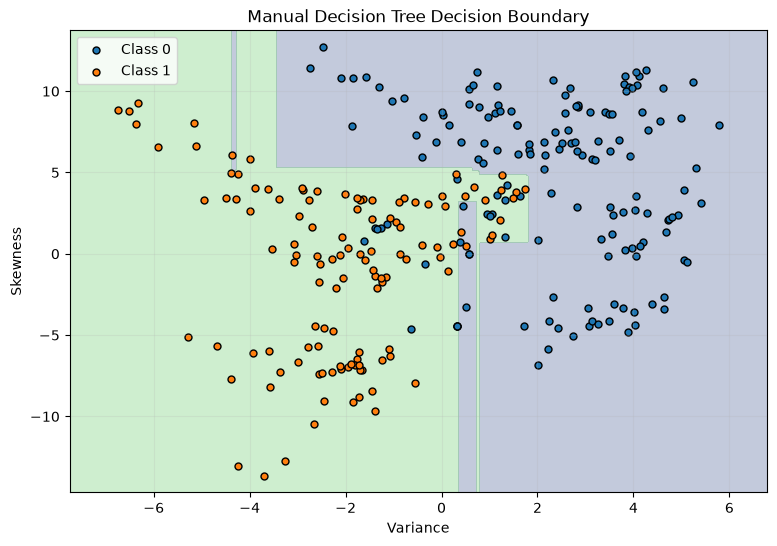

In [85]:
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    predictions = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(9, 6))
    plt.contourf(
        xx, yy, predictions,
        alpha=0.3, levels=[-0.5, 0.5, 1.5]
    )

    for label in np.unique(y):
        plt.scatter(
            X[y == label, 0],
            X[y == label, 1],
            label=f"Class {label}",
            edgecolors="black",
            s=25
        )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.2)
    plt.show()


plot_decision_boundary(
    manual_tree,
    X_test,
    y_test,
    "Manual Decision Tree Decision Boundary"
)

In [86]:
from sklearn.metrics import accuracy_score

manual_entropy_tree = ManualDecisionTree(
    criterion="entropy",
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1
)

start_time = time.perf_counter()
manual_entropy_tree.fit(X_train, y_train)
entropy_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
entropy_predictions = manual_entropy_tree.predict(X_test)
entropy_prediction_time = time.perf_counter() - start_time

print("Gini test accuracy:",
      accuracy_score(y_test, manual_tree.predict(X_test)))

print("Entropy test accuracy:",
      accuracy_score(y_test, entropy_predictions))

print("Entropy training time:", entropy_train_time, "seconds")
print("Entropy prediction time:", entropy_prediction_time, "seconds")

Gini test accuracy: 0.9309090909090909
Entropy test accuracy: 0.9345454545454546
Entropy training time: 0.3612853999948129 seconds
Entropy prediction time: 0.0003570999251678586 seconds


,max_depth,train_accuracy,test_accuracy,training_time_seconds
0,1,0.842297,0.829091,0.103742
1,2,0.901550,0.876364,0.195848
2,3,0.928897,0.909091,0.275512
3,5,0.948040,0.930909,0.527525
4,10,0.995442,0.920000,0.630760
5,None,1.000000,0.920000,0.527462


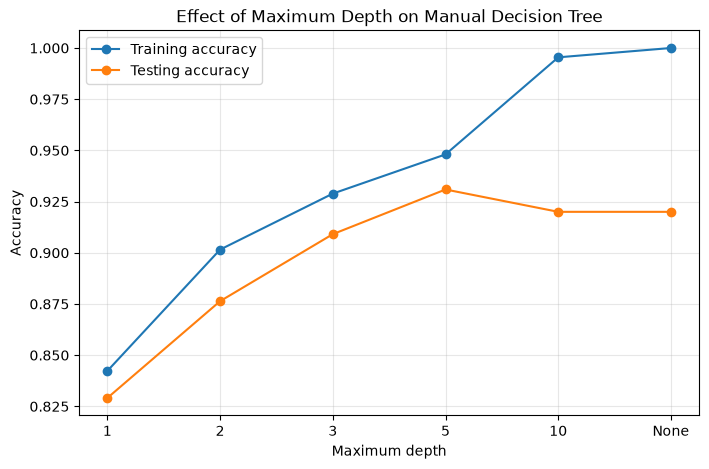

In [87]:
# Study the maximum depth
depth_results = []

for depth in [1, 2, 3, 5, 10, None]:
    model = ManualDecisionTree(
        criterion="gini",
        max_depth=depth
    )

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time

    train_accuracy = accuracy_score(
        y_train, model.predict(X_train)
    )
    test_accuracy = accuracy_score(
        y_test, model.predict(X_test)
    )

    depth_results.append({
        "max_depth": str(depth),
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "training_time_seconds": train_time
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)

plt.figure(figsize=(8, 5))
plt.plot(
    depth_df["max_depth"],
    depth_df["train_accuracy"],
    marker="o",
    label="Training accuracy"
)
plt.plot(
    depth_df["max_depth"],
    depth_df["test_accuracy"],
    marker="o",
    label="Testing accuracy"
)
plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Effect of Maximum Depth on Manual Decision Tree")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [88]:
# Compare against Scikit-learn
from sklearn.tree import DecisionTreeClassifier

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start_time = time.perf_counter()
sklearn_tree.fit(X_train, y_train)
sklearn_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_predictions = sklearn_tree.predict(X_test)
sklearn_prediction_time = time.perf_counter() - start_time

manual_predictions = manual_tree.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Manual Decision Tree",
        "Accuracy": accuracy_score(y_test, manual_predictions),
        "Precision": precision_score(
            y_test, manual_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, manual_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, manual_predictions, zero_division=0
        ),
        "Training time (s)": None,
        "Prediction time (s)": None
    },
    {
        "Model": "Scikit-learn Decision Tree",
        "Accuracy": accuracy_score(y_test, sklearn_predictions),
        "Precision": precision_score(
            y_test, sklearn_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, sklearn_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, sklearn_predictions, zero_division=0
        ),
        "Training time (s)": sklearn_train_time,
        "Prediction time (s)": sklearn_prediction_time
    }
])

display(comparison)

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Manual Decision Tree,0.930909,0.881481,0.97541,0.92607,NaN,NaN
1,Scikit-learn Decision Tree,0.930909,0.881481,0.97541,0.92607,0.004661,0.000716


In [89]:
# Complete the timing comparison
# Manual Decision Tree timing
manual_tree_timed = ManualDecisionTree(
    criterion="gini",
    max_depth=5
)

start_time = time.perf_counter()
manual_tree_timed.fit(X_train, y_train)
manual_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
manual_predictions_timed = manual_tree_timed.predict(X_test)
manual_prediction_time = time.perf_counter() - start_time

# Scikit-learn Decision Tree timing
sklearn_tree_timed = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start_time = time.perf_counter()
sklearn_tree_timed.fit(X_train, y_train)
sklearn_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_predictions_timed = sklearn_tree_timed.predict(X_test)
sklearn_prediction_time = time.perf_counter() - start_time

# Final Part A comparison
comparison_A = pd.DataFrame([
    {
        "Model": "Manual Decision Tree",
        "Accuracy": accuracy_score(y_test, manual_predictions_timed),
        "Precision": precision_score(y_test, manual_predictions_timed, zero_division=0),
        "Recall": recall_score(y_test, manual_predictions_timed, zero_division=0),
        "F1-score": f1_score(y_test, manual_predictions_timed, zero_division=0),
        "Training time (s)": manual_train_time,
        "Prediction time (s)": manual_prediction_time
    },
    {
        "Model": "Scikit-learn Decision Tree",
        "Accuracy": accuracy_score(y_test, sklearn_predictions_timed),
        "Precision": precision_score(y_test, sklearn_predictions_timed, zero_division=0),
        "Recall": recall_score(y_test, sklearn_predictions_timed, zero_division=0),
        "F1-score": f1_score(y_test, sklearn_predictions_timed, zero_division=0),
        "Training time (s)": sklearn_train_time,
        "Prediction time (s)": sklearn_prediction_time
    }
])

display(comparison_A.round(6))

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Manual Decision Tree,0.930909,0.881481,0.97541,0.92607,0.422369,0.000388
1,Scikit-learn Decision Tree,0.930909,0.881481,0.97541,0.92607,0.002404,0.000316


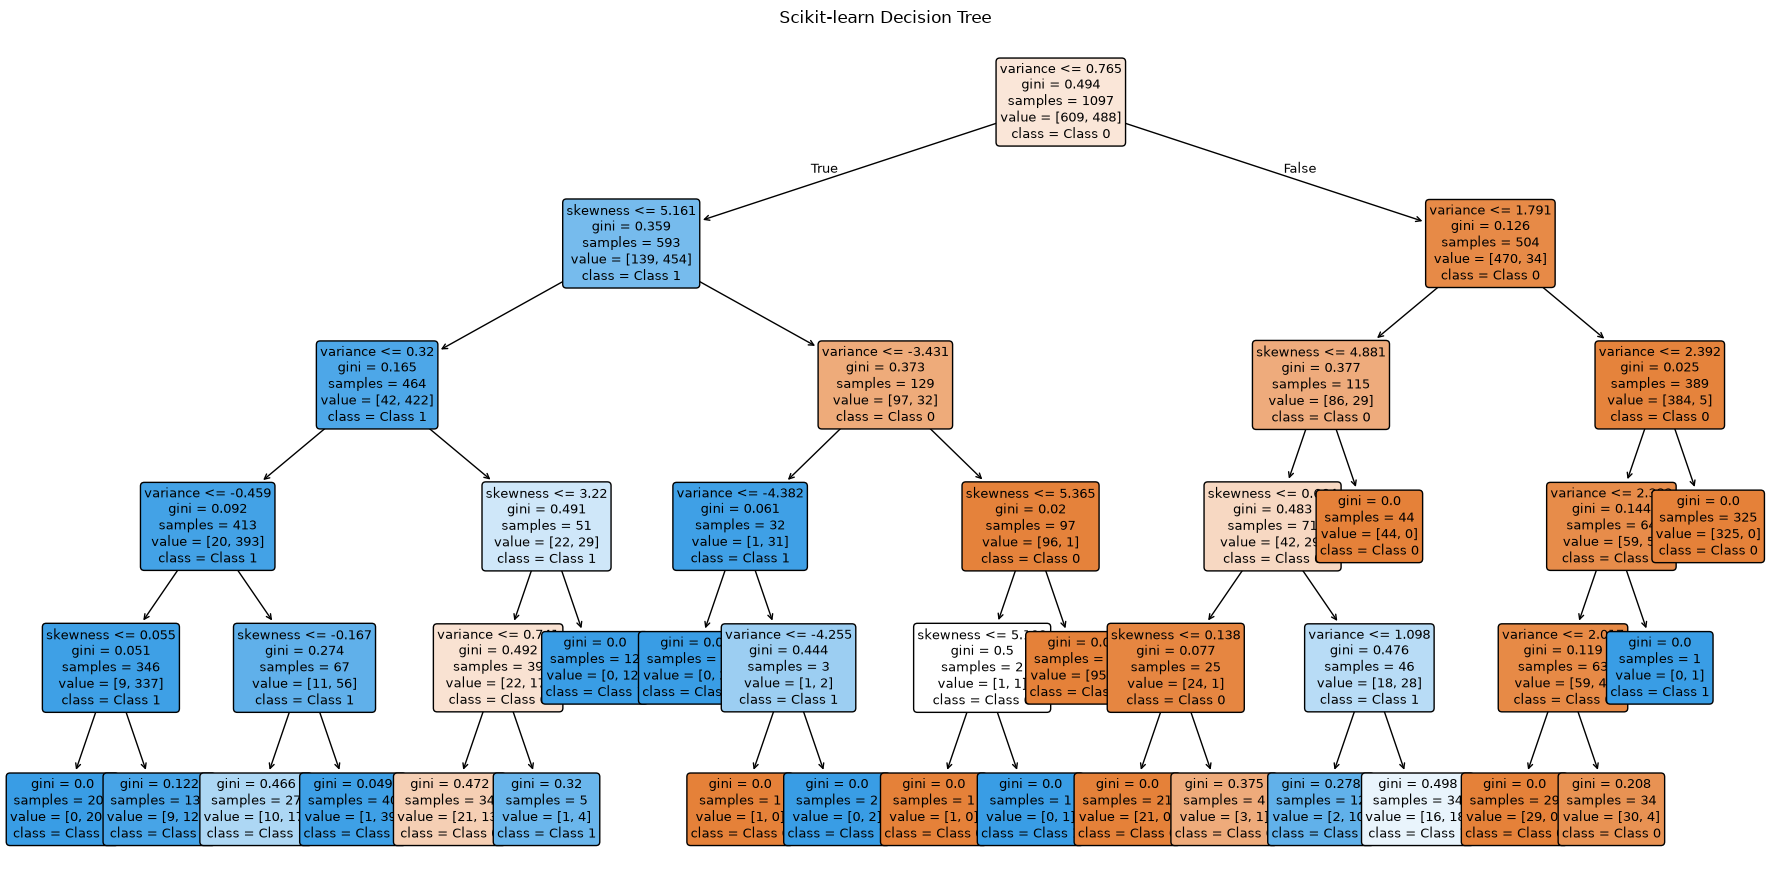

In [90]:
from sklearn.tree import plot_tree

plt.figure(figsize=(18, 9))

plot_tree(
    sklearn_tree_timed,
    feature_names=feature_names,
    class_names=["Class 0", "Class 1"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Scikit-learn Decision Tree")
plt.tight_layout()
plt.show()

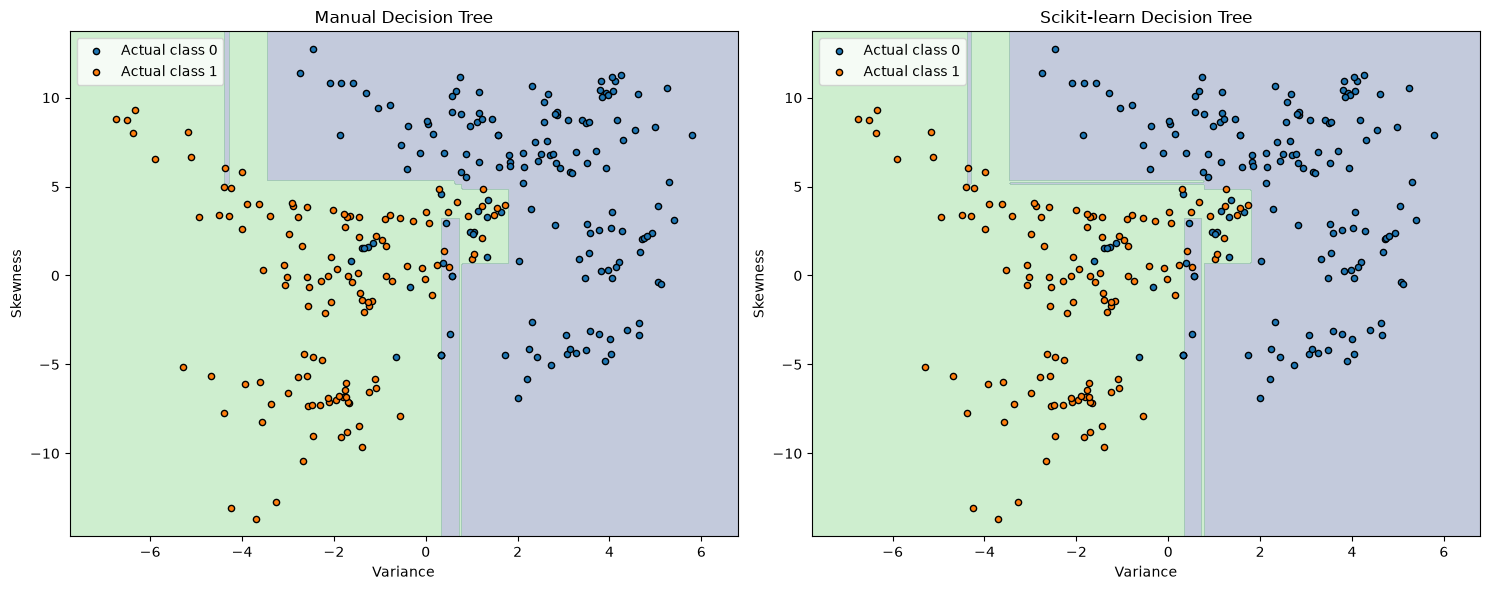

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

models = [
    (manual_tree_timed, "Manual Decision Tree"),
    (sklearn_tree_timed, "Scikit-learn Decision Tree")
]

for ax, (model, title) in zip(axes, models):
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.3
    )

    for label in np.unique(y_test):
        ax.scatter(
            X_test[y_test == label, 0],
            X_test[y_test == label, 1],
            label=f"Actual class {label}",
            s=20,
            edgecolors="black"
        )

    ax.set_xlabel("Variance")
    ax.set_ylabel("Skewness")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

,Max Depth,Train Accuracy,Test Accuracy,Training Time (s)
0,1,0.8423,0.8291,0.1145
1,2,0.9015,0.8764,0.2233
2,3,0.9289,0.9091,0.3762
3,5,0.9480,0.9309,0.5621
4,10,0.9954,0.9200,0.6413
5,None,1.0000,0.9200,0.6050


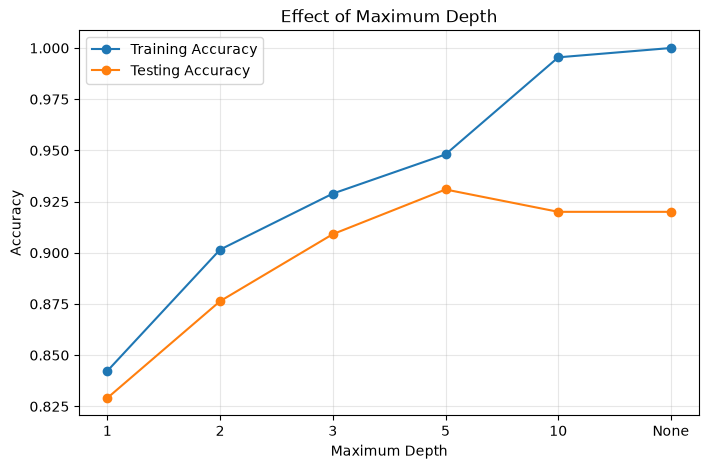

In [92]:
# Effect of Maximum Depth on Decision Tree Performanc
depth_results = []

for depth in [1, 2, 3, 5, 10, None]:
    model = ManualDecisionTree(
        criterion="gini",
        max_depth=depth
    )

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time

    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    depth_results.append({
        "Max Depth": str(depth),
        "Train Accuracy": accuracy_score(y_train, train_predictions),
        "Test Accuracy": accuracy_score(y_test, test_predictions),
        "Training Time (s)": train_time
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df.round(4))

plt.figure(figsize=(8, 5))
plt.plot(
    depth_df["Max Depth"],
    depth_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)
plt.plot(
    depth_df["Max Depth"],
    depth_df["Test Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Depth")
plt.ylabel("Accuracy")
plt.title("Effect of Maximum Depth")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [93]:
#Compare Gini and Entropy Criteria
criterion_results = []

for criterion in ["gini", "entropy"]:
    model = ManualDecisionTree(
        criterion=criterion,
        max_depth=5
    )

    start_time = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start_time

    predictions = model.predict(X_test)

    criterion_results.append({
        "Criterion": criterion,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "Training Time (s)": train_time
    })

criterion_df = pd.DataFrame(criterion_results)
display(criterion_df.round(4))

,Criterion,Accuracy,Precision,Recall,F1-score,Training Time (s)
0,gini,0.9309,0.8815,0.9754,0.9261,0.4452
1,entropy,0.9345,0.9000,0.9590,0.9286,0.4805


--------
## Part B — Linear SVM from Scratch

In [94]:
#Prepare and Standardize the Data

# Standardize using training-set statistics only
svm_mean = X_train.mean(axis=0)
svm_std = X_train.std(axis=0)

# Protect against division by zero
svm_std[svm_std == 0] = 1.0

X_train_svm = (X_train - svm_mean) / svm_std
X_test_svm = (X_test - svm_mean) / svm_std

# Convert labels from {0, 1} to {-1, +1}
y_train_svm = np.where(y_train == 1, 1.0, -1.0)
y_test_svm = np.where(y_test == 1, 1.0, -1.0)

print("Training data shape:", X_train_svm.shape)
print("Testing data shape:", X_test_svm.shape)
print("Training labels:", np.unique(y_train_svm))
print("Testing labels:", np.unique(y_test_svm))
print("Training feature means:", X_train_svm.mean(axis=0))
print("Training feature standard deviations:", X_train_svm.std(axis=0))

Training data shape: (1097, 2)
Testing data shape: (275, 2)
Training labels: [-1.  1.]
Testing labels: [-1.  1.]
Training feature means: [-8.72390380e-17 -3.24666861e-16]
Training feature standard deviations: [1. 1.]


In [95]:
# Implement Hinge Loss and the SVM Objective

def hinge_loss(X, y, w, b):
    margins = y * (X @ w + b)
    return np.maximum(0.0, 1.0 - margins)


def svm_objective(X, y, w, b, C):
    losses = hinge_loss(X, y, w, b)
    regularization = 0.5 * np.dot(w, w)

    return regularization + C * np.mean(losses)


# Small test example
test_X = np.array([[1.0, 2.0], [-1.0, -1.0]])
test_y = np.array([1.0, -1.0])
test_w = np.array([0.5, 0.5])
test_b = 0.0

print("Individual hinge losses:",
      hinge_loss(test_X, test_y, test_w, test_b))
print("Objective for C=1:",
      svm_objective(test_X, test_y, test_w, test_b, C=1.0))

Individual hinge losses: [0. 0.]
Objective for C=1: 0.25


In [97]:
#Implement Linear Soft-Margin SVM from Scratch

class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.01, n_iterations=2000):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.w = None
        self.b = 0.0
        self.loss_history = []

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features, dtype=float)
        self.b = 0.0
        self.loss_history = []

        for iteration in range(self.n_iterations):
            margins = y * (X @ self.w + self.b)
            violating = margins < 1.0

            # Gradient of 0.5 * ||w||^2
            dw = self.w.copy()

            # Add hinge-loss subgradient contributions
            if np.any(violating):
                dw -= self.C * np.mean(
                    (y[violating, None] * X[violating]),
                    axis=0
                ) * (np.sum(violating) / n_samples)

                db = -self.C * np.sum(y[violating]) / n_samples
            else:
                db = 0.0

            # Gradient descent update
            self.w -= self.learning_rate * dw
            self.b -= self.learning_rate * db

            self.loss_history.append(
                svm_objective(X, y, self.w, self.b, self.C)
            )

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0, 1, -1)

In [98]:
# Train and Evaluate the Manual SVM

manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.01,
    n_iterations=2000
)

start_time = time.perf_counter()
manual_svm.fit(X_train_svm, y_train_svm)
manual_svm_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
manual_svm_predictions = manual_svm.predict(X_test_svm)
manual_svm_prediction_time = time.perf_counter() - start_time

print("Learned weights:", manual_svm.w)
print("Learned bias:", manual_svm.b)
print("Final objective:", manual_svm.loss_history[-1])
print("Training time:", manual_svm_train_time, "seconds")
print("Prediction time:", manual_svm_prediction_time, "seconds")

manual_svm_predictions_01 = np.where(
    manual_svm_predictions == 1, 1, 0
)

print("Accuracy:",
      accuracy_score(y_test, manual_svm_predictions_01))
print("Precision:",
      precision_score(y_test, manual_svm_predictions_01, zero_division=0))
print("Recall:",
      recall_score(y_test, manual_svm_predictions_01, zero_division=0))
print("F1-score:",
      f1_score(y_test, manual_svm_predictions_01, zero_division=0))

Learned weights: [-0.49766283 -0.25958432]
Learned bias: -0.2874293527803052
Final objective: 0.6867726365670176
Training time: 0.17974599997978657 seconds
Prediction time: 6.600003689527512e-05 seconds
Accuracy: 0.8654545454545455
Precision: 0.9207920792079208
Recall: 0.7622950819672131
F1-score: 0.8340807174887892


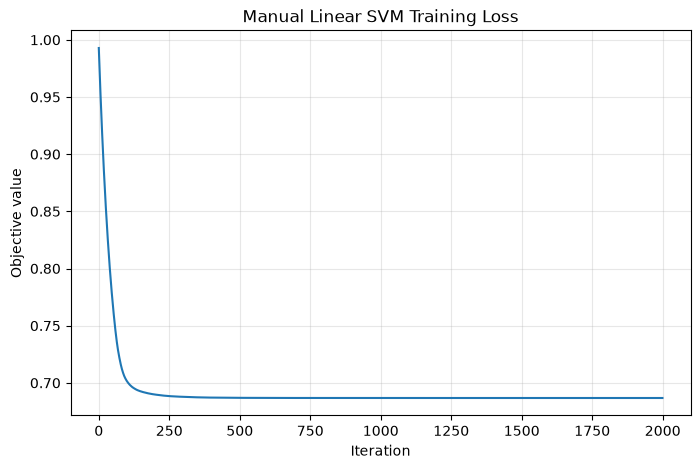

In [99]:
#Plot the SVM Objective During Training

plt.figure(figsize=(8, 5))
plt.plot(manual_svm.loss_history)
plt.xlabel("Iteration")
plt.ylabel("Objective value")
plt.title("Manual Linear SVM Training Loss")
plt.grid(alpha=0.3)
plt.show()

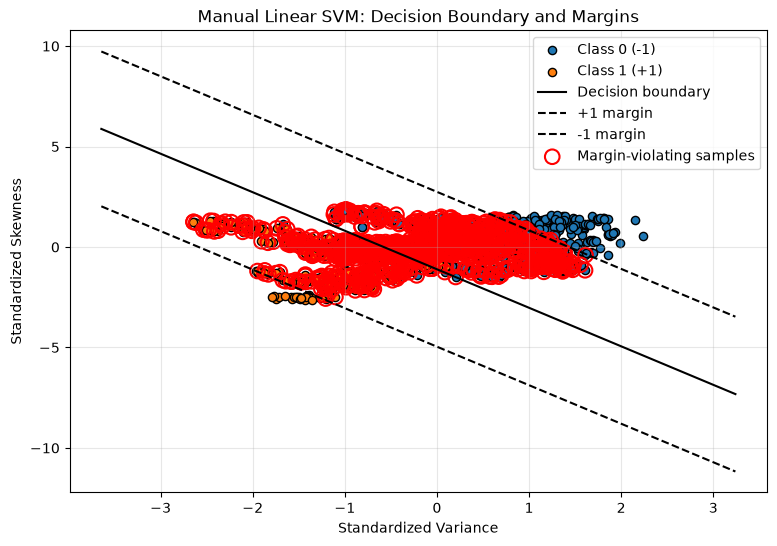

In [100]:
# Plot the Separating Line and Margins

def plot_manual_svm(model, X, y):
    plt.figure(figsize=(9, 6))

    for label, name in [(-1, "Class 0 (-1)"), (1, "Class 1 (+1)")]:
        plt.scatter(
            X[y == label, 0],
            X[y == label, 1],
            label=name,
            edgecolors="black",
            s=35
        )

    x_min = X[:, 0].min() - 1
    x_max = X[:, 0].max() + 1
    x_values = np.linspace(x_min, x_max, 400)

    w1, w2 = model.w

    if abs(w2) > 1e-12:
        decision_line = -(w1 * x_values + model.b) / w2
        upper_margin = (1 - model.b - w1 * x_values) / w2
        lower_margin = (-1 - model.b - w1 * x_values) / w2

        plt.plot(x_values, decision_line, "k-", label="Decision boundary")
        plt.plot(x_values, upper_margin, "k--", label="+1 margin")
        plt.plot(x_values, lower_margin, "k--", label="-1 margin")

    else:
        boundary_x = -model.b / w1
        plt.axvline(boundary_x, color="black", label="Decision boundary")
        plt.axvline(
            (-1 - model.b) / w1,
            color="gray",
            linestyle="--",
            label="Margin boundaries"
        )
        plt.axvline(
            (1 - model.b) / w1,
            color="gray",
            linestyle="--"
        )

    margins = y * model.decision_function(X)
    violating = margins < 1.0

    plt.scatter(
        X[violating, 0],
        X[violating, 1],
        s=110,
        facecolors="none",
        edgecolors="red",
        linewidths=1.5,
        label="Margin-violating samples"
    )

    plt.xlabel("Standardized Variance")
    plt.ylabel("Standardized Skewness")
    plt.title("Manual Linear SVM: Decision Boundary and Margins")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


plot_manual_svm(manual_svm, X_train_svm, y_train_svm)

In [101]:
# Compare Manual SVM with Scikit-learn Linear SVM

from sklearn.svm import SVC

sklearn_svm = SVC(kernel="linear", C=1.0)

start_time = time.perf_counter()
sklearn_svm.fit(X_train_svm, y_train_svm)
sklearn_svm_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
sklearn_svm_predictions = sklearn_svm.predict(X_test_svm)
sklearn_svm_prediction_time = time.perf_counter() - start_time

manual_predictions_01 = np.where(
    manual_svm.predict(X_test_svm) == 1, 1, 0
)

sklearn_predictions_01 = np.where(
    sklearn_svm_predictions == 1, 1, 0
)

svm_comparison = pd.DataFrame([
    {
        "Model": "Manual Linear SVM",
        "Accuracy": accuracy_score(y_test, manual_predictions_01),
        "Precision": precision_score(y_test, manual_predictions_01, zero_division=0),
        "Recall": recall_score(y_test, manual_predictions_01, zero_division=0),
        "F1-score": f1_score(y_test, manual_predictions_01, zero_division=0),
        "Training time (s)": manual_svm_train_time,
        "Prediction time (s)": manual_svm_prediction_time
    },
    {
        "Model": "Scikit-learn Linear SVM",
        "Accuracy": accuracy_score(y_test, sklearn_predictions_01),
        "Precision": precision_score(y_test, sklearn_predictions_01, zero_division=0),
        "Recall": recall_score(y_test, sklearn_predictions_01, zero_division=0),
        "F1-score": f1_score(y_test, sklearn_predictions_01, zero_division=0),
        "Training time (s)": sklearn_svm_train_time,
        "Prediction time (s)": sklearn_svm_prediction_time
    }
])

display(svm_comparison.round(6))

print(
    "Prediction agreement:",
    np.mean(manual_predictions_01 == sklearn_predictions_01)
)

,Model,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Manual Linear SVM,0.865455,0.920792,0.762295,0.834081,0.179746,0.000066
1,Scikit-learn Linear SVM,0.876364,0.849206,0.877049,0.862903,0.013939,0.002002


Prediction agreement: 0.9090909090909091


,C,Accuracy,Precision,Recall,F1-score,Training time (s),Final objective
0,0.01,0.56364,1.00000,0.01639,0.03226,0.23826,0.00994
1,0.10,0.56364,1.00000,0.01639,0.03226,0.21381,0.09404
2,1.00,0.86545,0.92079,0.76230,0.83408,0.22919,0.68677
3,10.00,0.88727,0.89565,0.84426,0.86920,0.17589,4.03840
4,100.00,0.88364,0.87500,0.86066,0.86777,0.18355,30.55245


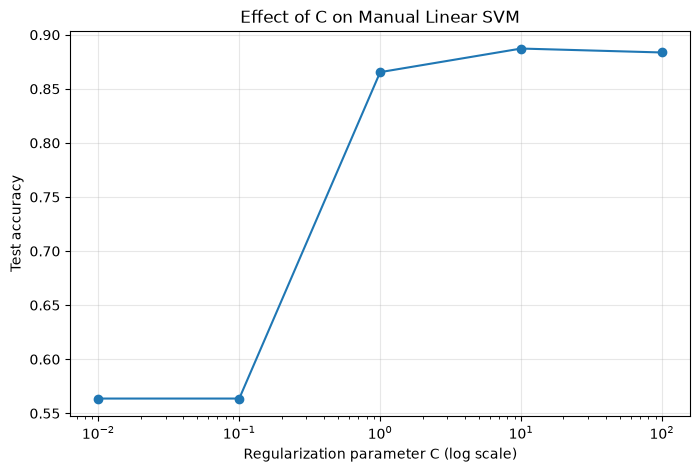

In [102]:
# Study the Effect of Regularization C

C_results = []

for C_value in [0.01, 0.1, 1.0, 10.0, 100.0]:
    model = ManualLinearSVM(
        C=C_value,
        learning_rate=0.01,
        n_iterations=2000
    )

    start_time = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start_time

    predictions = model.predict(X_test_svm)
    predictions_01 = np.where(predictions == 1, 1, 0)

    C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_test, predictions_01),
        "Precision": precision_score(y_test, predictions_01, zero_division=0),
        "Recall": recall_score(y_test, predictions_01, zero_division=0),
        "F1-score": f1_score(y_test, predictions_01, zero_division=0),
        "Training time (s)": train_time,
        "Final objective": model.loss_history[-1]
    })

C_df = pd.DataFrame(C_results)
display(C_df.round(5))

plt.figure(figsize=(8, 5))
plt.semilogx(C_df["C"], C_df["Accuracy"], marker="o")
plt.xlabel("Regularization parameter C (log scale)")
plt.ylabel("Test accuracy")
plt.title("Effect of C on Manual Linear SVM")
plt.grid(alpha=0.3)
plt.show()

,Learning Rate,Accuracy,F1-score,Final objective,Training time (s)
0,0.0001,0.88364,0.86777,0.88131,0.20638
1,0.0010,0.87636,0.85345,0.68982,0.18443
2,0.0100,0.86545,0.83408,0.68677,0.16843
3,0.0500,0.86545,0.83408,0.68677,0.15888
4,0.1000,0.86545,0.83408,0.68677,0.16930


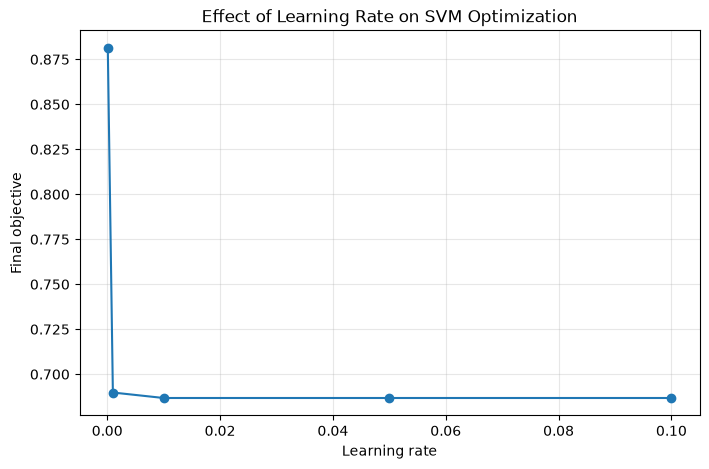

In [103]:
#  Study the Effect of Learning Rate

learning_rates = [0.0001, 0.001, 0.01, 0.05, 0.1]
lr_results = []

for lr in learning_rates:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=lr,
        n_iterations=2000
    )

    start_time = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start_time

    predictions = model.predict(X_test_svm)
    predictions_01 = np.where(predictions == 1, 1, 0)

    lr_results.append({
        "Learning Rate": lr,
        "Accuracy": accuracy_score(y_test, predictions_01),
        "F1-score": f1_score(y_test, predictions_01, zero_division=0),
        "Final objective": model.loss_history[-1],
        "Training time (s)": train_time
    })

lr_df = pd.DataFrame(lr_results)
display(lr_df.round(5))

plt.figure(figsize=(8, 5))
plt.plot(
    lr_df["Learning Rate"],
    lr_df["Final objective"],
    marker="o"
)
plt.xlabel("Learning rate")
plt.ylabel("Final objective")
plt.title("Effect of Learning Rate on SVM Optimization")
plt.grid(alpha=0.3)
plt.show()

,Iterations,Accuracy,F1-score,Final objective,Training time (s)
0,100,0.88727,0.86920,0.70178,0.01322
1,500,0.86545,0.83556,0.68692,0.05655
2,1000,0.86545,0.83408,0.68677,0.09095
3,2000,0.86545,0.83408,0.68677,0.15908
4,5000,0.86545,0.83408,0.68677,0.48891


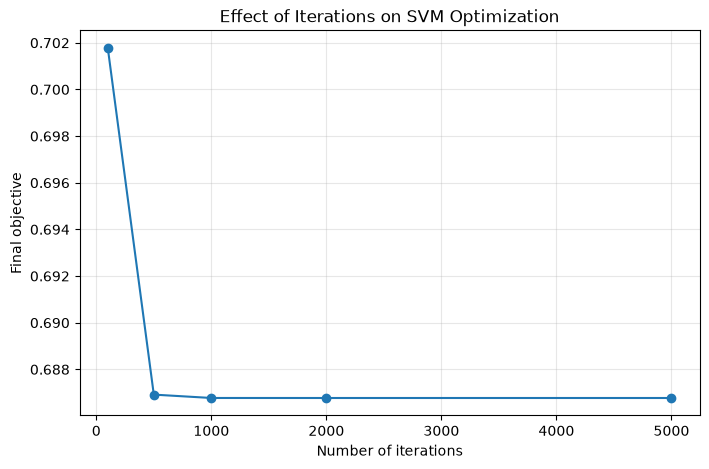

In [104]:
# Study the Effect of Number of Iterations

iteration_counts = [100, 500, 1000, 2000, 5000]
iteration_results = []

for n_iter in iteration_counts:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=0.01,
        n_iterations=n_iter
    )

    start_time = time.perf_counter()
    model.fit(X_train_svm, y_train_svm)
    train_time = time.perf_counter() - start_time

    predictions = model.predict(X_test_svm)
    predictions_01 = np.where(predictions == 1, 1, 0)

    iteration_results.append({
        "Iterations": n_iter,
        "Accuracy": accuracy_score(y_test, predictions_01),
        "F1-score": f1_score(y_test, predictions_01, zero_division=0),
        "Final objective": model.loss_history[-1],
        "Training time (s)": train_time
    })

iteration_df = pd.DataFrame(iteration_results)
display(iteration_df.round(5))

plt.figure(figsize=(8, 5))
plt.plot(
    iteration_df["Iterations"],
    iteration_df["Final objective"],
    marker="o"
)
plt.xlabel("Number of iterations")
plt.ylabel("Final objective")
plt.title("Effect of Iterations on SVM Optimization")
plt.grid(alpha=0.3)
plt.show()

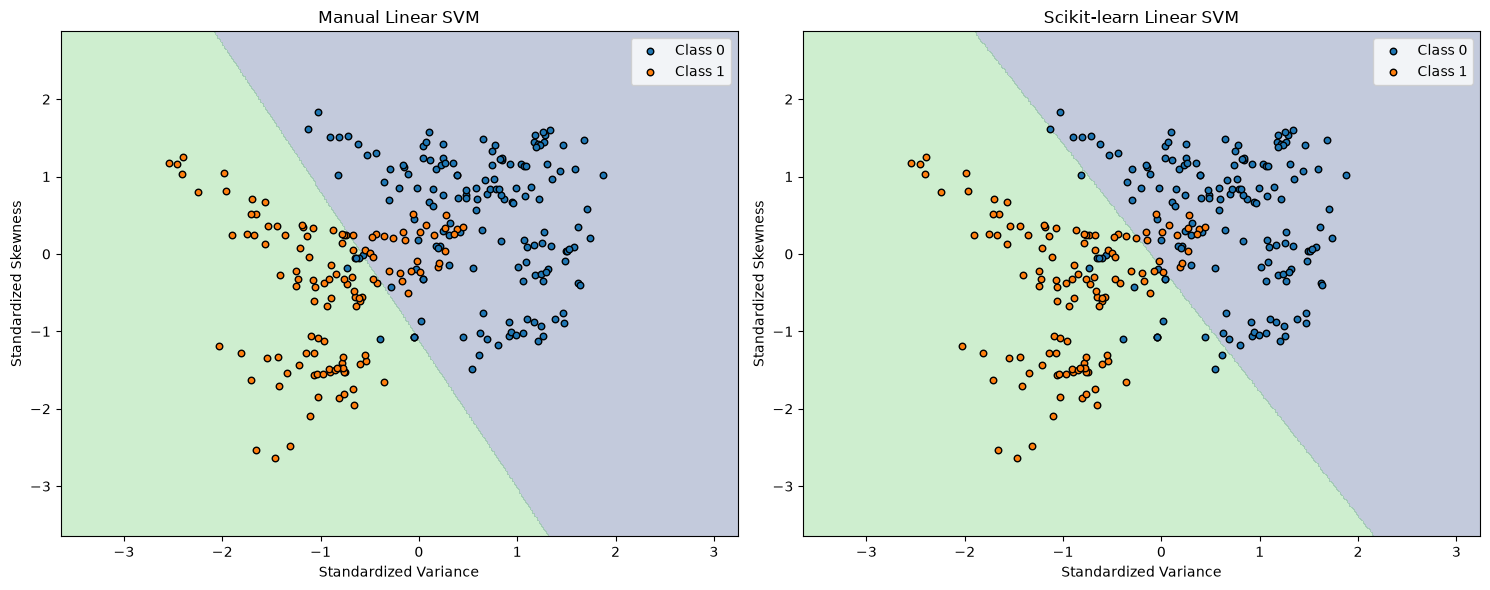

In [105]:
# Compare Manual and Scikit-learn SVM Decision Boundaries

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

x_min, x_max = X_train_svm[:, 0].min() - 1, X_train_svm[:, 0].max() + 1
y_min, y_max = X_train_svm[:, 1].min() - 1, X_train_svm[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

models = [
    (manual_svm, "Manual Linear SVM"),
    (sklearn_svm, "Scikit-learn Linear SVM")
]

for ax, (model, title) in zip(axes, models):
    Z = model.predict(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[-1.5, 0, 1.5],
        alpha=0.3
    )

    for label, name in [(-1, "Class 0"), (1, "Class 1")]:
        ax.scatter(
            X_test_svm[y_test_svm == label, 0],
            X_test_svm[y_test_svm == label, 1],
            label=name,
            s=22,
            edgecolors="black"
        )

    ax.set_xlabel("Standardized Variance")
    ax.set_ylabel("Standardized Skewness")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

----
## Part C — Kernel SVM and Nonlinear Boundaries

In [106]:
#Generate a Nonlinear Dataset

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X_moons, y_moons = make_moons(
    n_samples=1000,
    noise=0.25,
    random_state=42
)

X_moons_train, X_moons_test, y_moons_train, y_moons_test = (
    train_test_split(
        X_moons,
        y_moons,
        test_size=0.2,
        random_state=42,
        stratify=y_moons
    )
)

print("Dataset shape:", X_moons.shape)
print("Training samples:", len(X_moons_train))
print("Testing samples:", len(X_moons_test))
print("Classes:", np.unique(y_moons))

Dataset shape: (1000, 2)
Training samples: 800
Testing samples: 200
Classes: [0 1]


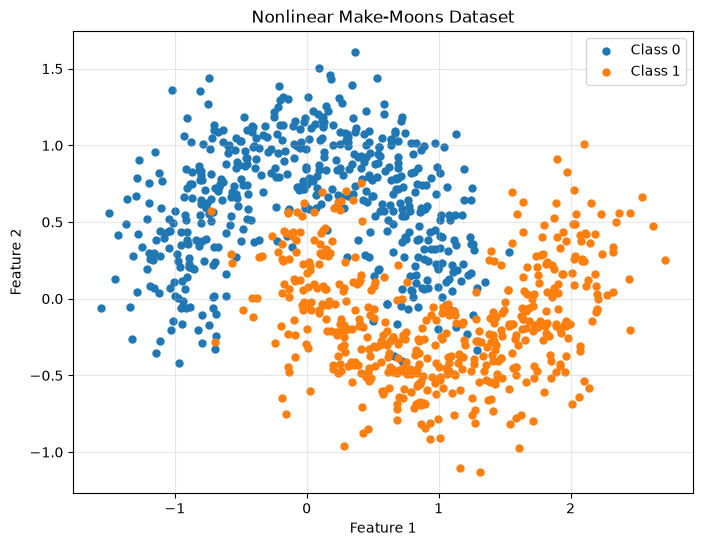

In [107]:
#  Visualize the Nonlinear Dataset

plt.figure(figsize=(8, 6))

for label in np.unique(y_moons):
    plt.scatter(
        X_moons[y_moons == label, 0],
        X_moons[y_moons == label, 1],
        label=f"Class {label}",
        s=25
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Make-Moons Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [108]:
# Standardize the Nonlinear Dataset

from sklearn.preprocessing import StandardScaler

moon_scaler = StandardScaler()

X_moons_train_scaled = moon_scaler.fit_transform(X_moons_train)
X_moons_test_scaled = moon_scaler.transform(X_moons_test)

print("Training feature means:",
      X_moons_train_scaled.mean(axis=0))
print("Training feature standard deviations:",
      X_moons_train_scaled.std(axis=0))

Training feature means: [ 3.10515502e-16 -8.82627305e-17]
Training feature standard deviations: [1. 1.]


In [109]:
#Train SVM Models with Different Kernels

from sklearn.svm import SVC

kernel_models = {
    "Linear": SVC(kernel="linear", C=1.0),
    "Polynomial": SVC(
        kernel="poly",
        degree=3,
        C=1.0,
        gamma="scale",
        coef0=1.0
    ),
    "RBF": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
}

kernel_training_times = {}
kernel_prediction_times = {}
kernel_predictions = {}

for name, model in kernel_models.items():
    start_time = time.perf_counter()
    model.fit(X_moons_train_scaled, y_moons_train)
    kernel_training_times[name] = time.perf_counter() - start_time

    start_time = time.perf_counter()
    predictions = model.predict(X_moons_test_scaled)
    kernel_prediction_times[name] = time.perf_counter() - start_time

    kernel_predictions[name] = predictions

    print(f"{name} SVM trained successfully.")

Linear SVM trained successfully.
Polynomial SVM trained successfully.
RBF SVM trained successfully.


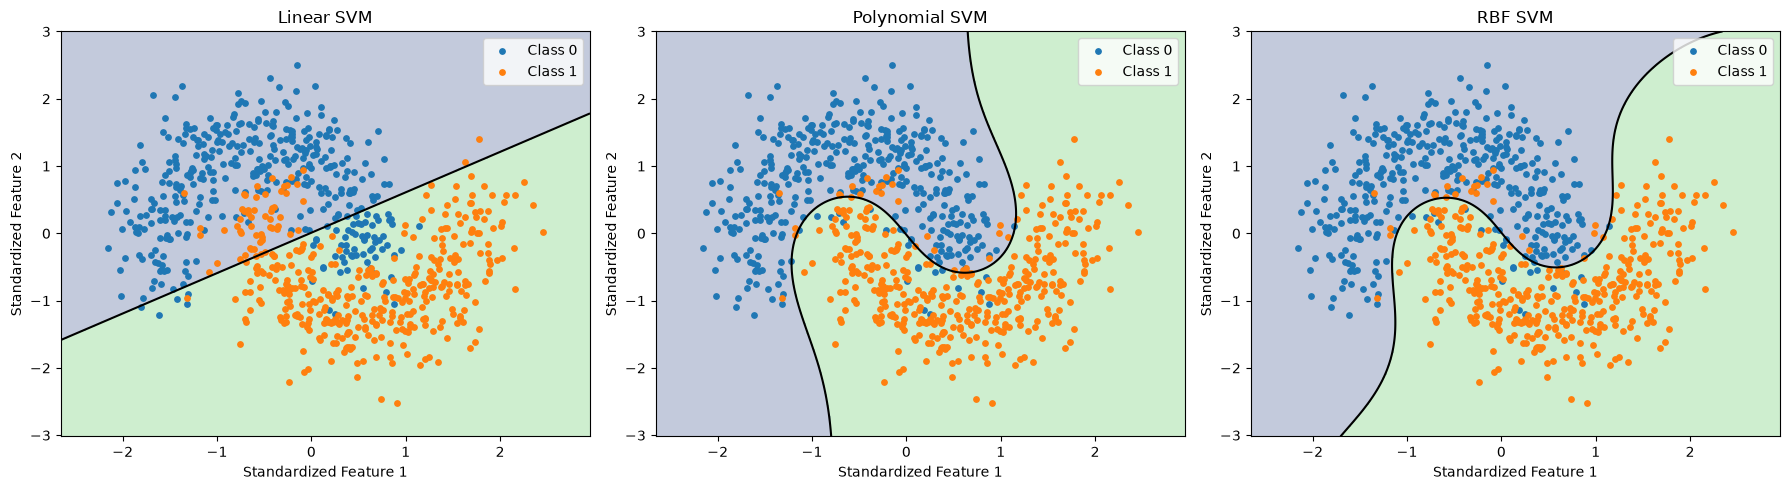

In [110]:
#Compare Linear, Polynomial and RBF Decision Boundaries

x_min = X_moons_train_scaled[:, 0].min() - 0.5
x_max = X_moons_train_scaled[:, 0].max() + 0.5
y_min = X_moons_train_scaled[:, 1].min() - 0.5
y_max = X_moons_train_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

moon_grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, model) in zip(axes, kernel_models.items()):
    Z = model.predict(moon_grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, Z,
        levels=[-0.5, 0.5, 1.5],
        alpha=0.3
    )

    ax.contour(
        xx, yy,
        model.decision_function(moon_grid).reshape(xx.shape),
        levels=[0],
        colors="black",
        linewidths=1.5
    )

    for label in np.unique(y_moons_train):
        ax.scatter(
            X_moons_train_scaled[y_moons_train == label, 0],
            X_moons_train_scaled[y_moons_train == label, 1],
            label=f"Class {label}",
            s=15
        )

    ax.set_title(f"{name} SVM")
    ax.set_xlabel("Standardized Feature 1")
    ax.set_ylabel("Standardized Feature 2")
    ax.legend()

plt.tight_layout()
plt.show()

In [111]:
# Evaluate the Kernel SVM Models

kernel_results = []

for name, model in kernel_models.items():
    predictions = kernel_predictions[name]

    kernel_results.append({
        "Kernel": name,
        "Accuracy": accuracy_score(y_moons_test, predictions),
        "Precision": precision_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_moons_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_moons_test, predictions, zero_division=0
        ),
        "Training time (s)": kernel_training_times[name],
        "Prediction time (s)": kernel_prediction_times[name]
    })

kernel_results_df = pd.DataFrame(kernel_results)
display(kernel_results_df.round(5))

,Kernel,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Linear,0.915,0.93684,0.89,0.91282,0.00862,0.00090
1,Polynomial,0.970,0.96078,0.98,0.97030,0.00585,0.00101
2,RBF,0.965,0.96040,0.97,0.96517,0.00602,0.00364


In [112]:
# Study the Effect of C and Gamma for RBF SVM

rbf_results = []

for C_value in [0.1, 1.0, 10.0]:
    for gamma_value in [0.1, 1.0, 10.0]:
        model = SVC(
            kernel="rbf",
            C=C_value,
            gamma=gamma_value
        )

        start_time = time.perf_counter()
        model.fit(X_moons_train_scaled, y_moons_train)
        train_time = time.perf_counter() - start_time

        predictions = model.predict(X_moons_test_scaled)

        rbf_results.append({
            "C": C_value,
            "Gamma": gamma_value,
            "Accuracy": accuracy_score(y_moons_test, predictions),
            "F1-score": f1_score(
                y_moons_test, predictions, zero_division=0
            ),
            "Training time (s)": train_time
        })

rbf_results_df = pd.DataFrame(rbf_results)
display(rbf_results_df.round(5))

,C,Gamma,Accuracy,F1-score,Training time (s)
0,0.1,0.1,0.915,0.91282,0.00918
1,0.1,1.0,0.970,0.97000,0.00600
2,0.1,10.0,0.985,0.98522,0.01372
3,1.0,0.1,0.930,0.92857,0.00565
4,1.0,1.0,0.970,0.97030,0.00369
5,1.0,10.0,0.985,0.98522,0.01000
6,10.0,0.1,0.960,0.96000,0.00573
7,10.0,1.0,0.975,0.97537,0.00503
8,10.0,10.0,0.975,0.97537,0.01105


In [113]:
# Observations

print("Kernel comparison:")
display(kernel_results_df.round(4))

best_kernel = kernel_results_df.loc[
    kernel_results_df["F1-score"].idxmax()
]

print("Highest test F1-score kernel:", best_kernel["Kernel"])
print("Its test F1-score:", round(best_kernel["F1-score"], 4))

Kernel comparison:


,Kernel,Accuracy,Precision,Recall,F1-score,Training time (s),Prediction time (s)
0,Linear,0.915,0.9368,0.89,0.9128,0.0086,0.0009
1,Polynomial,0.970,0.9608,0.98,0.9703,0.0058,0.0010
2,RBF,0.965,0.9604,0.97,0.9652,0.0060,0.0036


Highest test F1-score kernel: Polynomial
Its test F1-score: 0.9703


-------
## Part D — Compare All Models Using All Four Features

In [114]:
# Prepare the dataset using all four features

features = ["variance", "skewness", "curtosis", "entropy"]

X4 = df[features].to_numpy()
y4 = df["class"].to_numpy()

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4,
    y4,
    test_size=0.2,
    random_state=42,
    stratify=y4
)

print("Training samples:", len(X4_train))
print("Testing samples:", len(X4_test))
print("Number of features:", X4_train.shape[1])

Training samples: 1097
Testing samples: 275
Number of features: 4


In [115]:
# Train the manual Decision Tree

manual_tree4 = ManualDecisionTree(
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    criterion="gini"
)

start = time.perf_counter()
manual_tree4.fit(X4_train, y4_train)
manual_tree4_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_tree4_pred = manual_tree4.predict(X4_test)
manual_tree4_prediction_time = time.perf_counter() - start

print("Manual Decision Tree trained.")
print("Training time:", round(manual_tree4_train_time, 6), "seconds")
print("Prediction time:", round(manual_tree4_prediction_time, 6), "seconds")

Manual Decision Tree trained.
Training time: 0.82842 seconds
Prediction time: 0.000441 seconds


In [116]:
# Train the Scikit-learn Decision Tree

sklearn_tree4 = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

start = time.perf_counter()
sklearn_tree4.fit(X4_train, y4_train)
sklearn_tree4_train_time = time.perf_counter() - start

start = time.perf_counter()
sklearn_tree4_pred = sklearn_tree4.predict(X4_test)
sklearn_tree4_prediction_time = time.perf_counter() - start

print("Scikit-learn Decision Tree trained.")
print("Training time:", round(sklearn_tree4_train_time, 6), "seconds")
print("Prediction time:", round(sklearn_tree4_prediction_time, 6), "seconds")

Scikit-learn Decision Tree trained.
Training time: 0.003731 seconds
Prediction time: 0.000547 seconds


In [117]:
#Standardize features for SVM models

scaler4 = StandardScaler()

X4_train_scaled = scaler4.fit_transform(X4_train)
X4_test_scaled = scaler4.transform(X4_test)

y4_train_svm = np.where(y4_train == 1, 1.0, -1.0)
y4_test_svm = np.where(y4_test == 1, 1.0, -1.0)

print("Training data standardized.")
print("Scaled training shape:", X4_train_scaled.shape)
print("Scaled testing shape:", X4_test_scaled.shape)

Training data standardized.
Scaled training shape: (1097, 4)
Scaled testing shape: (275, 4)


In [118]:
#Train the Manual Linear SVM

manual_svm4 = ManualLinearSVM(
    C=1.0,
    learning_rate=0.001,
    n_iterations=5000
)

start = time.perf_counter()
manual_svm4.fit(X4_train_scaled, y4_train_svm)
manual_svm4_train_time = time.perf_counter() - start

start = time.perf_counter()
manual_svm4_raw_pred = manual_svm4.predict(X4_test_scaled)
manual_svm4_prediction_time = time.perf_counter() - start

# Convert -1/+1 predictions back to 0/1
manual_svm4_pred = np.where(np.asarray(manual_svm4_raw_pred) == 1, 1, 0)

print("Manual Linear SVM trained.")
print("Training time:", round(manual_svm4_train_time, 6), "seconds")
print("Prediction time:", round(manual_svm4_prediction_time, 6), "seconds")

Manual Linear SVM trained.
Training time: 0.518019 seconds
Prediction time: 0.000182 seconds


In [119]:
# Train the Scikit-learn Linear SVM

linear_svm4 = SVC(kernel="linear", C=1.0)

start = time.perf_counter()
linear_svm4.fit(X4_train_scaled, y4_train)
linear_svm4_train_time = time.perf_counter() - start

start = time.perf_counter()
linear_svm4_pred = linear_svm4.predict(X4_test_scaled)
linear_svm4_prediction_time = time.perf_counter() - start

print("Scikit-learn Linear SVM trained.")
print("Training time:", round(linear_svm4_train_time, 6), "seconds")
print("Prediction time:", round(linear_svm4_prediction_time, 6), "seconds")

Scikit-learn Linear SVM trained.
Training time: 0.010826 seconds
Prediction time: 0.000889 seconds


In [120]:
# Train the Scikit-learn RBF SVM

rbf_svm4 = SVC(kernel="rbf", C=1.0, gamma="scale")

start = time.perf_counter()
rbf_svm4.fit(X4_train_scaled, y4_train)
rbf_svm4_train_time = time.perf_counter() - start

start = time.perf_counter()
rbf_svm4_pred = rbf_svm4.predict(X4_test_scaled)
rbf_svm4_prediction_time = time.perf_counter() - start

print("Scikit-learn RBF SVM trained.")
print("Training time:", round(rbf_svm4_train_time, 6), "seconds")
print("Prediction time:", round(rbf_svm4_prediction_time, 6), "seconds")

Scikit-learn RBF SVM trained.
Training time: 0.00615 seconds
Prediction time: 0.002693 seconds


In [121]:
# Compare the performance of all five models

predictions4 = {
    "Manual Decision Tree": manual_tree4_pred,
    "Sklearn Decision Tree": sklearn_tree4_pred,
    "Manual Linear SVM": manual_svm4_pred,
    "Sklearn Linear SVM": linear_svm4_pred,
    "Sklearn RBF SVM": rbf_svm4_pred
}

training_times4 = {
    "Manual Decision Tree": manual_tree4_train_time,
    "Sklearn Decision Tree": sklearn_tree4_train_time,
    "Manual Linear SVM": manual_svm4_train_time,
    "Sklearn Linear SVM": linear_svm4_train_time,
    "Sklearn RBF SVM": rbf_svm4_train_time
}

prediction_times4 = {
    "Manual Decision Tree": manual_tree4_prediction_time,
    "Sklearn Decision Tree": sklearn_tree4_prediction_time,
    "Manual Linear SVM": manual_svm4_prediction_time,
    "Sklearn Linear SVM": linear_svm4_prediction_time,
    "Sklearn RBF SVM": rbf_svm4_prediction_time
}

results4 = []

for name, pred in predictions4.items():
    results4.append({
        "Model": name,
        "Accuracy": accuracy_score(y4_test, pred),
        "Precision": precision_score(y4_test, pred, zero_division=0),
        "Recall": recall_score(y4_test, pred, zero_division=0),
        "F1-score": f1_score(y4_test, pred, zero_division=0),
        "Training Time (s)": training_times4[name],
        "Prediction Time (s)": prediction_times4[name]
    })

results4_df = pd.DataFrame(results4)

display(
    results4_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}",
        "Training Time (s)": "{:.6f}",
        "Prediction Time (s)": "{:.6f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9927,0.9839,1.0000,0.9919,0.828420,0.000441
1,Sklearn Decision Tree,0.9927,0.9839,1.0000,0.9919,0.003731,0.000547
2,Manual Linear SVM,0.8800,0.9238,0.7951,0.8546,0.518019,0.000182
3,Sklearn Linear SVM,0.9745,0.9457,1.0000,0.9721,0.010826,0.000889
4,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.006150,0.002693


In [122]:
# Identify the best model by F1-score

best_model4 = results4_df.loc[results4_df["F1-score"].idxmax()]

print("Best model by F1-score:", best_model4["Model"])
print("F1-score:", round(best_model4["F1-score"], 4))
print("Accuracy:", round(best_model4["Accuracy"], 4))
print("Training time:", round(best_model4["Training Time (s)"], 6), "seconds")

Best model by F1-score: Sklearn RBF SVM
F1-score: 1.0
Accuracy: 1.0
Training time: 0.00615 seconds


In [123]:
# Compare model complexity

print("Scikit-learn Decision Tree")
print("Tree depth:", sklearn_tree4.get_depth())
print("Number of leaves:", sklearn_tree4.get_n_leaves())

print("\nScikit-learn Linear SVM")
print("Number of support vectors:", linear_svm4.n_support_.sum())

print("\nScikit-learn RBF SVM")
print("Number of support vectors:", rbf_svm4.n_support_.sum())

Scikit-learn Decision Tree
Tree depth: 5
Number of leaves: 20

Scikit-learn Linear SVM
Number of support vectors: 62

Scikit-learn RBF SVM
Number of support vectors: 91
